# ML vs DL for Early At-Risk Student Prediction (OULAD)

Starter pipeline for a comparative evaluation of classical machine learning
(Logistic Regression, Random Forest, XGBoost) and deep learning (LSTM, GRU)
for early identification of at-risk students, evaluated at multiple
prediction horizons on the **Open University Learning Analytics Dataset (OULAD)**.

**Runtime:** works on a free Colab GPU (`Runtime > Change runtime type > T4 GPU`).
Full run over 5 horizons takes roughly 20-40 minutes.

**Outputs:**
1. A results table (AUC, F1, at-risk recall, training time) per model per horizon
2. The "money figure": AUC vs. prediction week, one line per model
3. A SHAP summary plot for XGBoost (interpretability dimension)


In [ ]:
# --- Setup ---------------------------------------------------------------
!pip -q install shap

import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HORIZONS = [4, 8, 12, 16, 20]          # prediction points, in weeks from course start
KEY = ["code_module", "code_presentation", "id_student"]
print("Device:", DEVICE)

Device: cuda


## 1. Download OULAD

Downloads directly from the Open University. If the direct download fails,
search Kaggle for "OULAD", add it to the notebook via **Add data**, and point
`D` at that folder instead — the CSV file names are identical.


In [ ]:
# DATA_URL = "https://analyse.kmi.open.ac.uk/open_dataset/download"
# D = "oulad"

# if not os.path.exists(D):
#     print("Downloading OULAD (~430 MB unzipped)...")
#     urllib.request.urlretrieve(DATA_URL, "oulad.zip")
#     with zipfile.ZipFile("oulad.zip") as z:
#         z.extractall(D)
# print(sorted(os.listdir(D)))

import os
import zipfile
from google.colab import drive

# 1. Mount your Google Drive
drive.mount('/content/drive')

# 2. Define the paths
# Adjust 'notebooks' if your folder has a different name or path
zip_file_path = '/content/drive/MyDrive/Colab Notebooks/oulad.zip'
extract_to_dir = '/content/drive/MyDrive/Colab Notebooks/oulad_data'

# 3. Extract the contents directly into Drive
if not os.path.exists(extract_to_dir):
    print("Extracting OULAD from Google Drive...")
    with zipfile.ZipFile(zip_file_path, 'r') as z:
        z.extractall(extract_to_dir)
    print("Extraction complete!")
else:
    print("Directory already exists, skipping extraction.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting OULAD from Google Drive...
Extraction complete!


## 2. Labels and base cohort

At-risk = final result `Fail` or `Withdrawn`. Students who unregistered before
the course started are excluded (they never participated, so predicting them
is meaningless). Later, at each horizon we additionally drop students who had
already withdrawn by that week — an early-warning system only scores
*currently enrolled* students, and keeping withdrawn students would leak the label.


In [ ]:
df = info.merge(reg, on=KEY, how="left")
df = df[~(df.date_unregistration < 0)].copy()            # withdrew before start
df["at_risk"] = df.final_result.isin(["Fail", "Withdrawn"]).astype(int)
print("Class balance (1 = at-risk):")
print(df.at_risk.value_counts(normalize=True).round(3))

Class balance (1 = at-risk):
at_risk
0    0.514
1    0.486
Name: proportion, dtype: float64


## 3. Clickstream preparation

We attach the activity type to every click record and bucket days into weeks.
To keep the feature space manageable we keep the 10 most frequent activity
types and pool the rest into `other`.


In [ ]:
svle = svle.merge(vle[["id_site", "activity_type"]].drop_duplicates("id_site"),
                  on="id_site", how="left")
top_types = svle.activity_type.value_counts().head(10).index.tolist()
svle["atype"] = np.where(svle.activity_type.isin(top_types), svle.activity_type, "other")
TYPES = top_types + ["other"]
svle["week"] = (svle.date // 7).clip(lower=0)             # pre-course clicks -> week 0
print("Activity channels:", TYPES)

Activity channels: ['forumng', 'oucontent', 'subpage', 'homepage', 'quiz', 'resource', 'url', 'ouwiki', 'oucollaborate', 'externalquiz', 'other']


## 4. Feature engineering (classical models)

For a horizon of `H` weeks, classical models see hand-crafted aggregates of
everything observed strictly before day `H*7`:

* engagement: total clicks, clicks per activity type, active days, days since
  last activity, linear weekly click trend (slope)
* assessments: number submitted, mean score
* demographics: one-hot encoded (run your ablation with/without these)


In [ ]:
DEMO_CAT = ["gender", "highest_education", "imd_band", "age_band", "disability"]
DEMO_NUM = ["num_of_prev_attempts", "studied_credits"]

def build_tabular(H, cohort):
    hdays = H * 7
    clicks = svle[svle.date < hdays]

    g = clicks.groupby(KEY)
    feats = g.agg(total_clicks=("sum_click", "sum"),
                  active_days=("date", "nunique"),
                  last_day=("date", "max")).reset_index()
    feats["days_since_last"] = hdays - feats.last_day
    feats = feats.drop(columns="last_day")

    pt = clicks.pivot_table(index=KEY, columns="atype", values="sum_click",
                            aggfunc="sum", fill_value=0)
    pt = pt.add_prefix("clk_").reset_index()
    feats = feats.merge(pt, on=KEY, how="left")

    # vectorised least-squares slope of weekly clicks
    wk = clicks.groupby(KEY + ["week"]).sum_click.sum().reset_index()
    wk["w2"] = wk.week ** 2
    wk["wc"] = wk.week * wk.sum_click
    a = wk.groupby(KEY).agg(n=("week", "size"), sw=("week", "sum"),
                            sc=("sum_click", "sum"), sww=("w2", "sum"),
                            swc=("wc", "sum")).reset_index()
    den = a.n * a.sww - a.sw ** 2
    a["click_slope"] = np.where(den > 0, (a.n * a.swc - a.sw * a.sc) / den, 0.0)
    feats = feats.merge(a[KEY + ["click_slope"]], on=KEY, how="left")

    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[sa.date_submitted < hdays]
    ag = sa.groupby(KEY).agg(n_submitted=("score", "count"),
                             mean_score=("score", "mean")).reset_index()
    feats = feats.merge(ag, on=KEY, how="left")

    base = cohort.merge(feats, on=KEY, how="left")
    eng_cols = [c for c in base.columns if c.startswith("clk_")] +                ["total_clicks", "active_days", "days_since_last",
                "click_slope", "n_submitted", "mean_score"]
    base["days_since_last"] = base["days_since_last"].fillna(hdays)
    base[eng_cols] = base[eng_cols].fillna(0)

    X = pd.concat([base[eng_cols + DEMO_NUM],
                   pd.get_dummies(base[DEMO_CAT].fillna("unknown"))], axis=1)
    return X.astype(np.float32), base.at_risk.values

## 5. Sequence representation (deep models)

Deep models get the *raw* weekly multivariate time series instead of the
aggregates: an `(N, H, 11)` tensor of log-scaled weekly click counts per
activity channel. That asymmetry is the point of the comparison — can the
sequence models learn temporal structure the hand-crafted features miss?


In [ ]:
def build_sequences(H, cohort):
    clicks = svle[(svle.date >= 0) & (svle.date < H * 7)]
    wk = clicks.groupby(KEY + ["week", "atype"]).sum_click.sum().reset_index()

    ridx = cohort[KEY].copy()
    ridx["ridx"] = np.arange(len(ridx))
    wk = wk.merge(ridx, on=KEY, how="inner")

    t_idx = {t: i for i, t in enumerate(TYPES)}
    X = np.zeros((len(cohort), H, len(TYPES)), dtype=np.float32)
    X[wk.ridx.values, wk.week.values.astype(int), wk.atype.map(t_idx).values] = \
        np.log1p(wk.sum_click.values)
    return X

## 6. Models

Classical models use scikit-learn / XGBoost defaults plus class weighting —
sensible baselines you will later replace with an equal-budget Optuna search
per model (see the upgrade notes at the end). The deep models are deliberately
modest single-layer recurrent networks: deployment-scale, and they train in
minutes on a T4.


In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, n_feat, hidden=64, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_feat, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)


def train_rnn(Xtr, ytr, Xte, cell="lstm", epochs=30, patience=5, batch=256):
    itr, ival = train_test_split(np.arange(len(ytr)), test_size=0.1,
                                 stratify=ytr, random_state=SEED)
    def loader(idx, shuffle):
        ds = TensorDataset(torch.tensor(Xtr[idx]), torch.tensor(ytr[idx], dtype=torch.float32))
        return DataLoader(ds, batch_size=batch, shuffle=shuffle)

    model = RNNClassifier(Xtr.shape[2], cell=cell).to(DEVICE)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_auc, best_state, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in loader(itr, True):
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(torch.tensor(Xtr[ival]).to(DEVICE))).cpu().numpy()
        auc = roc_auc_score(ytr[ival], pv)
        if auc > best_auc:
            best_auc, wait = auc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        preds = torch.sigmoid(model(torch.tensor(Xte).to(DEVICE))).cpu().numpy()
    return preds

## 7. Experiment loop

For each horizon: build the cohort (still-enrolled students), build both data
representations from the **same students and the same split**, train all five
models, and record AUC, F1, at-risk recall (the metric an intervention system
actually cares about), and wall-clock training time.

The starter uses a stratified 80/20 split with a fixed seed. For the paper,
upgrade to (a) repeated runs over several seeds and (b) a cohort holdout —
train on 2013 presentations, test on 2014 — which tests generalisation to a
new academic year and is the more convincing protocol.


In [ ]:
import re
import time
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

results = []

for H in HORIZONS:
    print(f"\n=== Horizon: week {H} ===")
    hdays = H * 7
    cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= hdays)]
    cohort = cohort.reset_index(drop=True)

    Xtab, y = build_tabular(H, cohort)

    # ---- FIX: Clean column names for XGBoost right after creation ----
    regex = re.compile(r"\[|\]|<", re.IGNORECASE)
    Xtab.columns = [
        regex.sub("_", col) if any(x in str(col) for x in ["[", "]", "<"]) else col
        for col in Xtab.columns
    ]
    Xtab.columns = Xtab.columns.astype(str)
    # ------------------------------------------------------------------

    Xseq = build_sequences(H, cohort)
    tr, te = train_test_split(np.arange(len(y)), test_size=0.2,
                              stratify=y, random_state=SEED)
    print(f"cohort={len(y):,}  at-risk rate={y.mean():.3f}")

    def record(name, preds, secs):
        yhat = (preds >= 0.5).astype(int)
        results.append(dict(model=name, week=H,
                            auc=roc_auc_score(y[te], preds),
                            f1=f1_score(y[te], yhat),
                            recall_at_risk=recall_score(y[te], yhat),
                            train_secs=secs))
        print(f"  {name:12s} AUC={results[-1]['auc']:.3f}  "
              f"recall={results[-1]['recall_at_risk']:.3f}  ({secs:.0f}s)")

    # ---- classical -------------------------------------------------------
    scaler = StandardScaler().fit(Xtab.iloc[tr])
    t0 = time.time()
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(scaler.transform(Xtab.iloc[tr]), y[tr])
    record("LogReg", lr.predict_proba(scaler.transform(Xtab.iloc[te]))[:, 1], time.time() - t0)

    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=SEED, n_jobs=-1)
    rf.fit(Xtab.iloc[tr], y[tr])
    record("RandomForest", rf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    t0 = time.time()
    xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                tree_method="hist", eval_metric="auc",
                                scale_pos_weight=(y[tr] == 0).sum() / (y[tr] == 1).sum(),
                                random_state=SEED)
    xgb_clf.fit(Xtab.iloc[tr], y[tr])
    record("XGBoost", xgb_clf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    # ---- deep ------------------------------------------------------------
    for cell_type in ["lstm", "gru"]:
        t0 = time.time()
        preds = train_rnn(Xseq[tr], y[tr], Xseq[te], cell=cell_type)
        record(cell_type.upper(), preds, time.time() - t0)

res = pd.DataFrame(results)
res.round(3)


=== Horizon: week 4 ===
cohort=27,553  at-risk rate=0.442
  LogReg       AUC=0.735  recall=0.655  (0s)
  RandomForest AUC=0.773  recall=0.578  (18s)
  XGBoost      AUC=0.780  recall=0.669  (3s)
  LSTM         AUC=0.717  recall=0.637  (14s)
  GRU          AUC=0.711  recall=0.685  (6s)

=== Horizon: week 8 ===
cohort=26,532  at-risk rate=0.420
  LogReg       AUC=0.776  recall=0.661  (0s)
  RandomForest AUC=0.819  recall=0.606  (11s)
  XGBoost      AUC=0.813  recall=0.676  (4s)
  LSTM         AUC=0.762  recall=0.628  (9s)
  GRU          AUC=0.761  recall=0.646  (10s)

=== Horizon: week 12 ===
cohort=25,733  at-risk rate=0.402
  LogReg       AUC=0.811  recall=0.670  (0s)
  RandomForest AUC=0.835  recall=0.596  (13s)
  XGBoost      AUC=0.833  recall=0.679  (3s)
  LSTM         AUC=0.776  recall=0.633  (7s)
  GRU          AUC=0.779  recall=0.638  (8s)

=== Horizon: week 16 ===
cohort=24,941  at-risk rate=0.383
  LogReg       AUC=0.854  recall=0.711  (0s)
  RandomForest AUC=0.869  recall=0.64

,model,week,auc,f1,recall_at_risk,train_secs
0,LogReg,4,0.735,0.636,0.655,0.258
1,RandomForest,4,0.773,0.636,0.578,17.886
2,XGBoost,4,0.780,0.675,0.669,2.734
3,LSTM,4,0.717,0.625,0.637,13.615
4,GRU,4,0.711,0.633,0.685,5.958
5,LogReg,8,0.776,0.660,0.661,0.256
6,RandomForest,8,0.819,0.676,0.606,11.443
7,XGBoost,8,0.813,0.695,0.676,3.835
8,LSTM,8,0.762,0.637,0.628,8.778
9,GRU,8,0.761,0.642,0.646,10.065


## 8. The money figure: AUC vs. prediction horizon

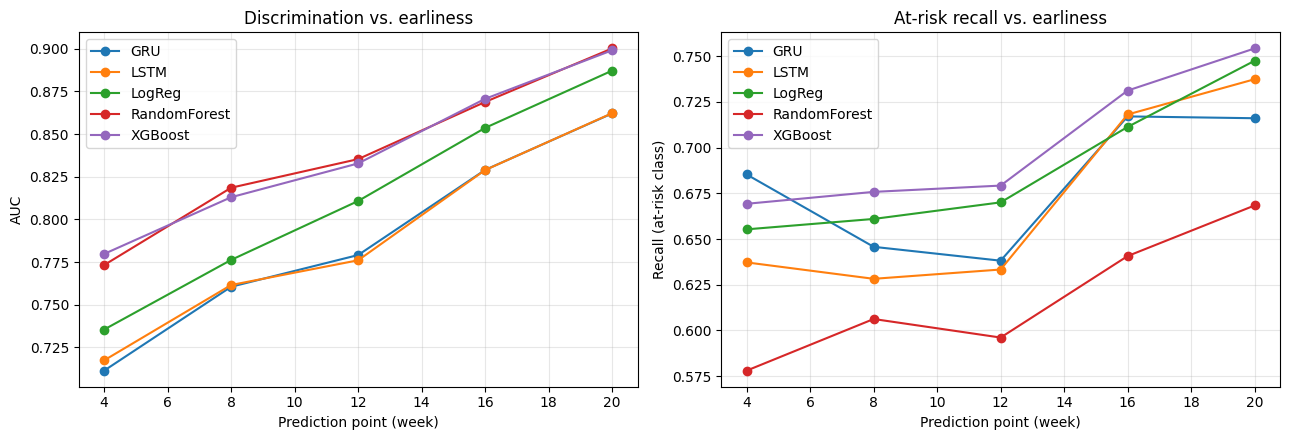

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, g in res.groupby("model"):
    axes[0].plot(g.week, g.auc, marker="o", label=m)
    axes[1].plot(g.week, g.recall_at_risk, marker="o", label=m)
axes[0].set(xlabel="Prediction point (week)", ylabel="AUC",
            title="Discrimination vs. earliness")
axes[1].set(xlabel="Prediction point (week)", ylabel="Recall (at-risk class)",
            title="At-risk recall vs. earliness")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("auc_vs_horizon.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Interpretability: SHAP for XGBoost (week 8)

Re-trains XGBoost at the week-8 horizon and plots SHAP values — the
interpretability dimension of your comparison. For the deep models, the
analogous analysis is attention weights or integrated gradients (e.g. via
`captum`), which you can compare qualitatively in the paper.


/tmp/ipykernel_817/1966954042.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample_data, max_display=15)


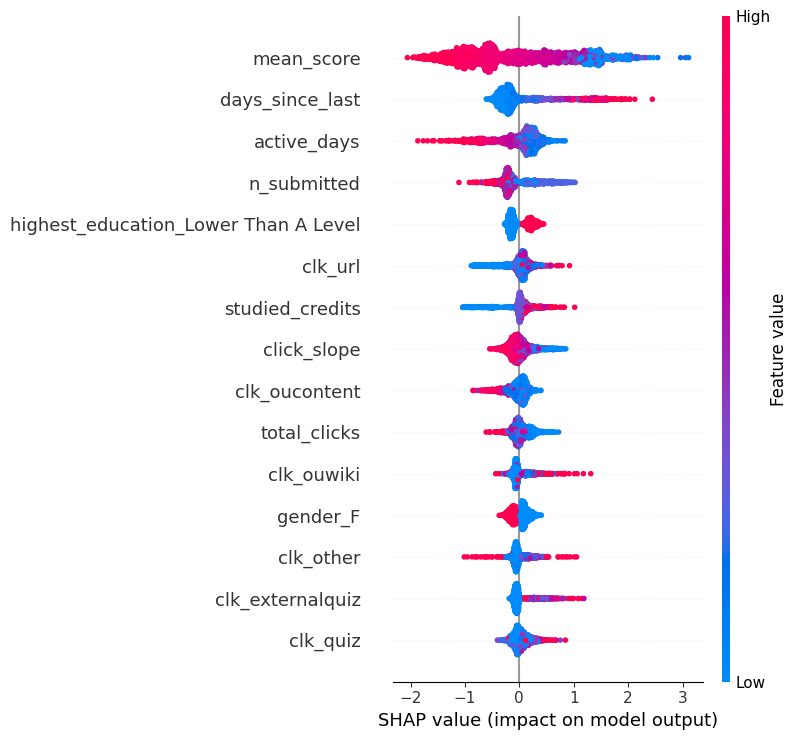

In [ ]:
import re
import shap
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split

H = 8
cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= H * 7)]
cohort = cohort.reset_index(drop=True)

# 1. Generate the tabular data
Xtab, y = build_tabular(H, cohort)

# ---- FIX: Clean column names for XGBoost right after creation ----
regex = re.compile(r"\[|\]|<", re.IGNORECASE)
Xtab.columns = [
    regex.sub("_", col) if any(x in str(col) for x in ["[", "]", "<"]) else col
    for col in Xtab.columns
]
Xtab.columns = Xtab.columns.astype(str)
# ------------------------------------------------------------------

# 2. Split data
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)

# 3. Train the model
model = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          tree_method="hist", random_state=SEED)
model.fit(Xtab.iloc[tr], y[tr])

# 4. Run SHAP explanations
explainer = shap.TreeExplainer(model)
sample_data = Xtab.iloc[te].sample(2000, random_state=SEED)
sv = explainer.shap_values(sample_data)

# 5. Generate plot
shap.summary_plot(sv, sample_data, max_display=15)

## 10. Upgrades before submission

1. **Cohort holdout** — train on `code_presentation` values ending in `2013B/2013J`,
   test on `2014B/2014J`. Replaces the random split and tests generalisation to
   a new academic year.
2. **Repeated runs + significance** — 5 seeds per model per horizon, then a
   Friedman test with post-hoc Nemenyi (or pairwise Wilcoxon) across models.
   `scipy.stats` and the `scikit-posthocs` package cover both.
3. **Equal tuning budget** — replace the default hyperparameters with an
   Optuna search of ~30 trials per model, identical budget for classical and
   deep, and report the search spaces in a table.
4. **More deep baselines** — a 1D-CNN and a small transformer encoder slot
   directly into `train_rnn`'s place; both train fine on a T4.
5. **Ablations** — with/without demographics (fairness angle), and
   sequence-only vs. sequence+assessment channels.
6. **Cost table** — you're already logging `train_secs`; add per-student
   inference time and peak GPU memory (`torch.cuda.max_memory_allocated()`).
